In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from transformers import AutoTokenizer

df = pd.read_csv("../data/financial_sentiment.csv")

df = df.drop_duplicates(subset=["sentence"]).reset_index(drop=True)

print("Clean Dataset:", df.shape)

/home/pasali/anaconda3/envs/myenv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Clean Dataset: (2259, 2)


In [2]:
X = df["sentence"]
y = df["label"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

train_df = pd.DataFrame({
    "sentence": X_train,
    "label": y_train
})

val_df = pd.DataFrame({
    "sentence": X_val,
    "label": y_val
})

test_df = pd.DataFrame({
    "sentence": X_test,
    "label": y_test
})

In [3]:
MODEL_NAME = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer:", tokenizer.__class__.__name__)
print("Vocabulary Size:", tokenizer.vocab_size)

Tokenizer: BertTokenizer
Vocabulary Size: 30522


In [4]:
assert len(df) == 2259
assert len(train_df) == 1807
assert len(val_df) == 226
assert len(test_df) == 226

assert set(train_df["sentence"]).isdisjoint(val_df["sentence"])
assert set(train_df["sentence"]).isdisjoint(test_df["sentence"])
assert set(val_df["sentence"]).isdisjoint(test_df["sentence"])

for split in [train_df, val_df, test_df]:
    assert set(split["label"].unique()) == {0, 1, 2}

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("Data Preparation: PASSED")

Train: (1807, 2)
Validation: (226, 2)
Test: (226, 2)
Data Preparation: PASSED


In [ ]:
train_df["word_count"] = [len(words) for words in train_df["sentence"].str.split()]
val_df["word_count"] = [len(words) for words in val_df["sentence"].str.split()]

print(train_df.head(5))
print(val_df.head(5))

                                               sentence  label  word_count
457   Earnings per share for the quarter were also h...      2          24
1574  The company continued the development of a ful...      1          16
1996  The company operates a U.S. division in Lisle ...      1          11
1311                                     NWC ANALYSIS :      1           3
2231  The hull of the vessel was built one block at ...      1          25
                                               sentence  label  word_count
275   Aldata said that there are still a number of o...      1          39
77    - Operating profit rose by 26.9 % to EUR 105.8...      2          15
107   Diluted earnings per share ( EPS ) rose to EUR...      2          15
1871  Finnish technology company Raute Corporation (...      0          27
1370  The acquisition was financed with $ 2.56 billi...      1          18


In [16]:
def create_token(sentence):
    result = tokenizer(
        sentence,
        truncation=False,
        padding=False
    )

    return len(result["input_ids"])


train_df["token_count"] = train_df["sentence"].apply(create_token)
val_df["token_count"] = val_df["sentence"].apply(create_token)

print(train_df[["sentence", "word_count", "token_count"]].head())

                                               sentence  word_count  \
457   Earnings per share for the quarter were also h...          24   
1574  The company continued the development of a ful...          16   
1996  The company operates a U.S. division in Lisle ...          11   
1311                                     NWC ANALYSIS :           3   
2231  The hull of the vessel was built one block at ...          25   

      token_count  
457            38  
1574           21  
1996           18  
1311            6  
2231           29  


In [19]:
train_df["token_word_ratio"] = train_df["token_count"] / train_df["word_count"]
val_df["token_word_ratio"] = val_df["token_count"] / val_df["word_count"]

print(train_df.head(5))

                                               sentence  label  word_count  \
457   Earnings per share for the quarter were also h...      2          24   
1574  The company continued the development of a ful...      1          16   
1996  The company operates a U.S. division in Lisle ...      1          11   
1311                                     NWC ANALYSIS :      1           3   
2231  The hull of the vessel was built one block at ...      1          25   

      token_count  token_word_ratio  
457            38          1.583333  
1574           21          1.312500  
1996           18          1.636364  
1311            6          2.000000  
2231           29          1.160000  


In [24]:
train_quantiles = train_df["token_count"].describe(percentiles=[0.50,0.90,0.95,0.99])
val_quantiles = val_df["token_count"].describe(percentiles=[0.50,0.90,0.95,0.99])

train_quantiles

count    1807.000000
mean       29.969009
std        13.773767
min         4.000000
50%        27.000000
90%        49.000000
95%        57.000000
99%        69.000000
max       150.000000
Name: token_count, dtype: float64

In [34]:
token_lengths = pd.DataFrame({"train" : train_quantiles, 
              "val " : val_quantiles})

token_lengths

,train,val
count,1807.000000,226.000000
mean,29.969009,30.699115
std,13.773767,13.090037
min,4.000000,7.000000
50%,27.000000,28.000000
90%,49.000000,50.500000
95%,57.000000,57.000000
99%,69.000000,64.000000
max,150.000000,67.000000


In [29]:
train_truncated = (train_df["token_count"] > 128).sum()
val_truncated = (val_df["token_count"] > 128).sum()

train_truncation_rate = train_truncated / len(train_df) * 100
val_truncation_rate = val_truncated / len(val_df) * 100

print("Train truncated:", train_truncated)
print("Train truncation rate:", train_truncation_rate)

print("Validation truncated:", val_truncated)
print("Validation truncation rate:", val_truncation_rate)

Train truncated: 1
Train truncation rate: 0.05534034311012728
Validation truncated: 0
Validation truncation rate: 0.0


In [31]:
train_df.groupby("label")["token_count"].describe(percentiles=[0.50 ,0.90 ,0.95 , 0.99])

,count,mean,std,min,50%,90%,95%,99%,max
label,,,,,,,,,
0,242.0,33.504132,13.524297,7.0,31.0,55.8,61.00,67.59,75.0
1,1109.0,27.506763,13.110582,4.0,25.0,45.0,51.00,65.92,150.0
2,456.0,34.081140,14.113979,9.0,31.0,56.5,62.25,70.90,80.0


In [32]:
val_df.groupby("label")["token_count"].describe(percentiles=[0.50 ,0.90 ,0.95 , 0.99])

,count,mean,std,min,50%,90%,95%,99%,max
label,,,,,,,,,
0,30.0,35.233333,11.918353,16.0,33.5,49.1,60.65,64.13,65.0
1,139.0,26.935252,11.493671,7.0,25.0,43.4,50.10,58.34,62.0
2,57.0,37.491228,14.007808,14.0,34.0,57.4,62.40,65.32,67.0


In [35]:
token_lengths.to_csv("../reports/token_length_statistics.csv")

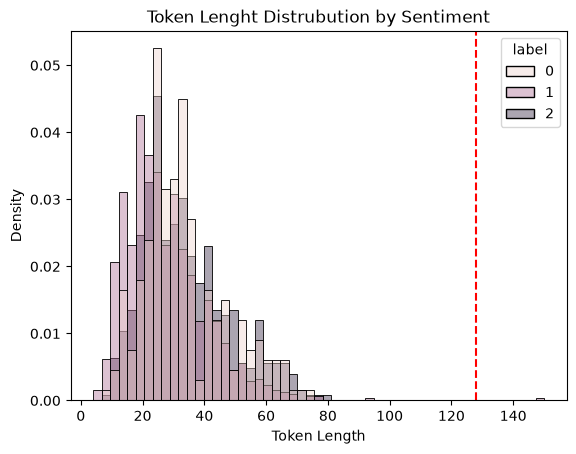

In [57]:
import seaborn as sns
import matplotlib.pyplot as plt


sns.histplot(data=train_df , x="token_count" , hue="label" , stat="density",common_norm=False , multiple="layer" , alpha=0.4)
plt.axvline(x=128, color="red", linestyle="--", label="Max Length = 128")
plt.ylabel("Density")
plt.xlabel("Token Length")
plt.title("Token Lenght Distrubution by Sentiment")
plt.savefig("../figures/token_length_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


In [58]:
from scipy.stats import kruskal

negative = train_df[train_df["label"] == 0]["token_count"]

neutral = train_df[train_df["label"] == 1]["token_count"]

positive = train_df[train_df["label"] == 2]["token_count"]


statistic, p_value = kruskal(negative, neutral, positive)

print("Statistic:", statistic)
print("P-value:", p_value)

Statistic: 102.6362642511274
P-value: 5.162004707761248e-23


In [59]:
from scipy.stats import mannwhitneyu

statistic, p_value = mannwhitneyu(
    negative,
    neutral,
    alternative="two-sided"
)

print("P-value:", p_value)

P-value: 1.3798866690828412e-11


In [60]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

class_names = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

pairs = [(0, 1), (0, 2), (1, 2)]

results = []

for class_a, class_b in pairs:
    group_a = train_df.loc[train_df["label"] == class_a, "token_count"]
    group_b = train_df.loc[train_df["label"] == class_b, "token_count"]

    statistic, p_value = mannwhitneyu(
        group_a,
        group_b,
        alternative="two-sided"
    )

    rank_biserial = 2 * statistic / (len(group_a) * len(group_b)) - 1

    results.append({
        "Class A": class_names[class_a],
        "Class B": class_names[class_b],
        "Mean A": group_a.mean(),
        "Mean B": group_b.mean(),
        "U Statistic": statistic,
        "P-value": p_value,
        "Effect Size": rank_biserial
    })

posthoc_df = pd.DataFrame(results)

posthoc_df

,Class A,Class B,Mean A,Mean B,U Statistic,P-value,Effect Size
0,Negative,Neutral,33.504132,27.506763,171347.5,1.379887e-11,0.276912
1,Negative,Positive,33.504132,34.081140,54380.0,7.536103e-01,-0.014427
2,Neutral,Positive,27.506763,34.081140,180669.0,6.191535e-19,-0.285475


In [61]:
reject, adjusted_p, _, _ = multipletests(
    posthoc_df["P-value"],
    alpha=0.05,
    method="holm"
)

posthoc_df["Adjusted P-value"] = adjusted_p
posthoc_df["Significant"] = reject

posthoc_df

,Class A,Class B,Mean A,Mean B,U Statistic,P-value,Effect Size,Adjusted P-value,Significant
0,Negative,Neutral,33.504132,27.506763,171347.5,1.379887e-11,0.276912,2.759773e-11,True
1,Negative,Positive,33.504132,34.081140,54380.0,7.536103e-01,-0.014427,7.536103e-01,False
2,Neutral,Positive,27.506763,34.081140,180669.0,6.191535e-19,-0.285475,1.857461e-18,True


In [62]:
posthoc_df.to_csv(
    "../reports/token_length_posthoc.csv",
    index=False
)

In [63]:
features = ["word_count", "token_count", "token_word_ratio"]

X_train = train_df[features]
y_train = train_df["label"]

X_val = val_df[features]
y_val = val_df["label"]

In [64]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

length_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

length_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['word_count','token_count','token_word_ratio']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [65]:
from sklearn.metrics import classification_report, f1_score, accuracy_score

predictions = length_model.predict(X_val)

print(classification_report(
    y_val,
    predictions,
    target_names=["Negative", "Neutral", "Positive"],
    zero_division=0
))

print("Accuracy:", accuracy_score(y_val, predictions))
print("Macro-F1:", f1_score(y_val, predictions, average="macro"))

              precision    recall  f1-score   support

    Negative       0.17      0.23      0.20        30
     Neutral       0.84      0.66      0.74       139
    Positive       0.41      0.54      0.47        57

    accuracy                           0.58       226
   macro avg       0.47      0.48      0.47       226
weighted avg       0.64      0.58      0.60       226

Accuracy: 0.5752212389380531
Macro-F1: 0.4683737456090024


In [66]:
max_lengths = [128, 256]

for max_length in max_lengths:
    lost_tokens = (train_df["token_count"] - max_length).clip(lower=0)

    truncated_samples = (lost_tokens > 0).sum()
    truncation_rate = truncated_samples / len(train_df) * 100
    total_lost_tokens = lost_tokens.sum()
    avg_lost_tokens = lost_tokens.mean()

    print(f"Max Length: {max_length}")
    print(f"Truncated Samples: {truncated_samples}")
    print(f"Truncation Rate: {truncation_rate:.4f}%")
    print(f"Lost Tokens: {total_lost_tokens}")
    print(f"Average Lost Tokens: {avg_lost_tokens:.4f}")
    print("-" * 40)

Max Length: 128
Truncated Samples: 1
Truncation Rate: 0.0553%
Lost Tokens: 22
Average Lost Tokens: 0.0122
----------------------------------------
Max Length: 256
Truncated Samples: 0
Truncation Rate: 0.0000%
Lost Tokens: 0
Average Lost Tokens: 0.0000
----------------------------------------


In [68]:
longest_sentences= train_df.nlargest(5, "token_count")
longest_sentences

,sentence,label,word_count,token_count,token_word_ratio
762,"Supported Nokia phones include : N96 , N95-8GB...",1,81,150,1.851852
1136,3 January 2011 - Scandinavian lenders Sampo Ba...,1,57,93,1.631579
343,narrows to EUR2 .8 m 9-mo '09 29 October 2009 ...,2,55,80,1.454545
829,"MANAVIGATOR-September 7 , 2010-Kemira unveils ...",2,47,77,1.638298
910,1 p.m. Central office of Nordea Bank 19 3-ya u...,1,40,77,1.925000


In [69]:
sentence = longest_sentences.iloc[0]["sentence"]

print(sentence)

Supported Nokia phones include : N96 , N95-8GB , N95 , N93-N931 , N92 , N85 , N82 , N81 , N80 , N79 , N78 , N77 , N76 , N75 , N73 , N72 , N71 , E90 , E71 , E70 , E66 , E65 , E62 , E61-E61i , E60 , E51 , E50 , Touch Xpress 5800 , 6220 Classic , 6210 Navigator , 6120 Classic , 6110 Navigator , 5700 , 5500 , 5320XM .


In [70]:
encoded_128 = tokenizer(
    sentence,
    truncation=True,
    max_length=128,
    padding=False
)

encoded_256 = tokenizer(
    sentence,
    truncation=True,
    max_length=256,
    padding=False
)

text_128 = tokenizer.decode(
    encoded_128["input_ids"],
    skip_special_tokens=True
)

text_256 = tokenizer.decode(
    encoded_256["input_ids"],
    skip_special_tokens=True
)

print("Original:", sentence)
print("\n128 Tokens:", text_128)
print("\n256 Tokens:", text_256)

Original: Supported Nokia phones include : N96 , N95-8GB , N95 , N93-N931 , N92 , N85 , N82 , N81 , N80 , N79 , N78 , N77 , N76 , N75 , N73 , N72 , N71 , E90 , E71 , E70 , E66 , E65 , E62 , E61-E61i , E60 , E51 , E50 , Touch Xpress 5800 , 6220 Classic , 6210 Navigator , 6120 Classic , 6110 Navigator , 5700 , 5500 , 5320XM .

128 Tokens: supported nokia phones include : n96, n95 - 8gb, n95, n93 - n931, n92, n85, n82, n81, n80, n79, n78, n77, n76, n75, n73, n72, n71, e90, e71, e70, e66, e65, e62, e61 - e61i, e60, e51, e50, touch xpress 5800, 6220 classic, 62

256 Tokens: supported nokia phones include : n96, n95 - 8gb, n95, n93 - n931, n92, n85, n82, n81, n80, n79, n78, n77, n76, n75, n73, n72, n71, e90, e71, e70, e66, e65, e62, e61 - e61i, e60, e51, e50, touch xpress 5800, 6220 classic, 6210 navigator, 6120 classic, 6110 navigator, 5700, 5500, 5320xm.


In [71]:
original_ids = tokenizer.encode(
    sentence,
    add_special_tokens=False
)

lost_ids = original_ids[126:]

lost_text = tokenizer.decode(lost_ids)

print("Lost token count:", len(lost_ids))
print("Lost text:", lost_text)

Lost token count: 22
Lost text: ##10 navigator, 6120 classic, 6110 navigator, 5700, 5500, 5320xm.


In [72]:
train_df["truncated_128"] = train_df["token_count"] > 128

class_truncation = train_df.groupby("label")["truncated_128"].mean() * 100

print(class_truncation)

label
0    0.000000
1    0.090171
2    0.000000
Name: truncated_128, dtype: float64


In [73]:
results = []

for split_name, df in [("train", train_df), ("validation", val_df)]:
    for max_length in [128, 256]:
        lost_tokens = (df["token_count"] - max_length).clip(lower=0)

        truncated_samples = (lost_tokens > 0).sum()
        truncation_rate = truncated_samples / len(df) * 100

        class_rates = (
            df.assign(truncated=lost_tokens > 0)
            .groupby("label")["truncated"]
            .mean() * 100
        )

        results.append({
            "split": split_name,
            "max_length": max_length,
            "truncated_samples": truncated_samples,
            "truncation_rate": truncation_rate,
            "lost_tokens": lost_tokens.sum(),
            "avg_lost_tokens": lost_tokens.mean(),
            "negative_truncation_rate": class_rates.get(0, 0),
            "neutral_truncation_rate": class_rates.get(1, 0),
            "positive_truncation_rate": class_rates.get(2, 0)
        })

truncation_analysis = pd.DataFrame(results)

truncation_analysis.to_csv(
    "../reports/truncation_analysis.csv",
    index=False
)

truncation_analysis

,split,max_length,truncated_samples,truncation_rate,lost_tokens,avg_lost_tokens,negative_truncation_rate,neutral_truncation_rate,positive_truncation_rate
0,train,128,1,0.05534,22,0.012175,0.0,0.090171,0.0
1,train,256,0,0.00000,0,0.000000,0.0,0.000000,0.0
2,validation,128,0,0.00000,0,0.000000,0.0,0.000000,0.0
3,validation,256,0,0.00000,0,0.000000,0.0,0.000000,0.0


In [80]:
import gc
import time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    set_seed
)

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)


def compute_metrics(eval_pred):
    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    precision, recall, macro_f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    _, class_recalls, _, _ = precision_recall_fscore_support(
        labels,
        predictions,
        labels=[0, 1, 2],
        average=None,
        zero_division=0
    )

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": macro_f1,
        "negative_recall": class_recalls[0],
        "neutral_recall": class_recalls[1],
        "positive_recall": class_recalls[2]
    }

In [81]:
def run_experiment(max_length):
    if max_length not in [128, 256]:
        raise ValueError("max_length must be 128 or 256")

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    set_seed(42)

    model_name = "distilbert-base-uncased"

    tokenizer = AutoTokenizer.from_pretrained(model_name)

    train_dataset = Dataset.from_pandas(
        train_df[["sentence", "label"]],
        preserve_index=False
    )

    val_dataset = Dataset.from_pandas(
        val_df[["sentence", "label"]],
        preserve_index=False
    )

    def tokenize_function(batch):
        return tokenizer(
            batch["sentence"],
            truncation=True,
            max_length=max_length,
            padding=False
        )

    tokenized_train = train_dataset.map(
        tokenize_function,
        batched=True,
        remove_columns=["sentence"]
    )

    tokenized_val = val_dataset.map(
        tokenize_function,
        batched=True,
        remove_columns=["sentence"]
    )

    data_collator = DataCollatorWithPadding(
        tokenizer=tokenizer
    )

    id2label = {
        0: "Negative",
        1: "Neutral",
        2: "Positive"
    }

    label2id = {
        "Negative": 0,
        "Neutral": 1,
        "Positive": 2
    }

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=3,
        id2label=id2label,
        label2id=label2id
    )

    training_args = TrainingArguments(
        output_dir=f"../models/length_resource_experiment_{max_length}",
        num_train_epochs=3,
        learning_rate=2e-5,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,
        weight_decay=0.01,
        warmup_steps=34,
        gradient_accumulation_steps=1,
        lr_scheduler_type="linear",
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        seed=42,
        data_seed=42,
        logging_strategy="epoch",
        report_to="none"
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=tokenized_train,
        eval_dataset=tokenized_val,
        processing_class=tokenizer,
        data_collator=data_collator,
        compute_metrics=compute_metrics
    )

    try:
        if torch.cuda.is_available():
            torch.cuda.synchronize()
            torch.cuda.reset_peak_memory_stats()

        start_time = time.perf_counter()

        train_result = trainer.train()

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        training_time = time.perf_counter() - start_time

        if torch.cuda.is_available():
            peak_gpu_memory = (
                torch.cuda.max_memory_allocated() / 1_000_000
            )
        else:
            peak_gpu_memory = np.nan

        val_metrics = trainer.evaluate()

        best_checkpoint = trainer.state.best_model_checkpoint

        best_step = int(best_checkpoint.rsplit("-", 1)[-1])

        best_epoch = next(
            (
                entry["epoch"]
                for entry in trainer.state.log_history
                if entry.get("step") == best_step
                and "eval_macro_f1" in entry
            ),
            None
        )

        results = {
            "max_length": max_length,
            "train_loss": train_result.training_loss,
            "val_loss": val_metrics["eval_loss"],
            "val_accuracy": val_metrics["eval_accuracy"],
            "val_macro_f1": val_metrics["eval_macro_f1"],
            "val_macro_precision": val_metrics["eval_macro_precision"],
            "val_macro_recall": val_metrics["eval_macro_recall"],
            "val_negative_recall": val_metrics["eval_negative_recall"],
            "val_neutral_recall": val_metrics["eval_neutral_recall"],
            "val_positive_recall": val_metrics["eval_positive_recall"],
            "training_time_s": training_time,
            "peak_gpu_memory_mb": peak_gpu_memory,
            "best_epoch": best_epoch,
            "global_step": trainer.state.global_step,
            "best_checkpoint": best_checkpoint
        }

        return results

    finally:
        del trainer
        del model

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

In [82]:
results_128 = run_experiment(128)

print(results_128)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 18737.96it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Negative Recall,Neutral Recall,Positive Recall
1,0.658000,0.274818,0.911504,0.857400,0.870525,0.863270,0.833333,0.971223,0.807018
2,0.168328,0.225709,0.915929,0.892560,0.935374,0.909614,0.966667,0.892086,0.947368
3,0.075345,0.115270,0.964602,0.947096,0.953040,0.949958,0.933333,0.978417,0.947368


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  8.77it/s]


Training Loss,Validation Loss,Epoch,Accuracy,Macro Precision,Macro Recall,Macro F1,Negative Recall,Neutral Recall,Positive Recall
0.075345,0.115270,3,0.964602,0.947096,0.953040,0.949958,0.933333,0.978417,0.947368


{'max_length': 128, 'train_loss': 0.30055792141804655, 'val_loss': 0.11527049541473389, 'val_accuracy': 0.9646017699115044, 'val_macro_f1': 0.9499583541562552, 'val_macro_precision': 0.9470961001828254, 'val_macro_recall': 0.9530396735243384, 'val_negative_recall': 0.9333333333333333, 'val_neutral_recall': 0.9784172661870504, 'val_positive_recall': 0.9473684210526315, 'training_time_s': 18.043862634000106, 'peak_gpu_memory_mb': 1514.970624, 'best_epoch': 3.0, 'global_step': 339, 'best_checkpoint': '../models/length_resource_experiment_128/checkpoint-339'}


In [83]:
results_256 = run_experiment(256)

print(results_256)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 15967.35it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Negative Recall,Neutral Recall,Positive Recall
1,0.657382,0.272653,0.915929,0.862615,0.872923,0.866966,0.833333,0.978417,0.807018
2,0.166145,0.192419,0.924779,0.906349,0.934907,0.916806,0.933333,0.906475,0.964912
3,0.069649,0.117045,0.969027,0.950717,0.967601,0.958797,0.966667,0.971223,0.964912


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  9.17it/s]


Training Loss,Validation Loss,Epoch,Accuracy,Macro Precision,Macro Recall,Macro F1,Negative Recall,Neutral Recall,Positive Recall
0.069649,0.117045,3,0.969027,0.950717,0.967601,0.958797,0.966667,0.971223,0.964912


{'max_length': 256, 'train_loss': 0.2977253047414234, 'val_loss': 0.11704546958208084, 'val_accuracy': 0.9690265486725663, 'val_macro_f1': 0.9587973573853675, 'val_macro_precision': 0.9507168458781362, 'val_macro_recall': 0.9676006563170515, 'val_negative_recall': 0.9666666666666667, 'val_neutral_recall': 0.9712230215827338, 'val_positive_recall': 0.9649122807017544, 'training_time_s': 18.08749500600061, 'peak_gpu_memory_mb': 1633.617408, 'best_epoch': 3.0, 'global_step': 339, 'best_checkpoint': '../models/length_resource_experiment_256/checkpoint-339'}


In [84]:
comparison_df = pd.DataFrame([
    results_128,
    results_256
])

comparison_df.to_csv(
    "../reports/sequence_length_comparison.csv",
    index=False
)

display(comparison_df.T)

,0,1
max_length,128,256
train_loss,0.300558,0.297725
val_loss,0.11527,0.117045
val_accuracy,0.964602,0.969027
val_macro_f1,0.949958,0.958797
val_macro_precision,0.947096,0.950717
val_macro_recall,0.95304,0.967601
val_negative_recall,0.933333,0.966667
val_neutral_recall,0.978417,0.971223
val_positive_recall,0.947368,0.964912


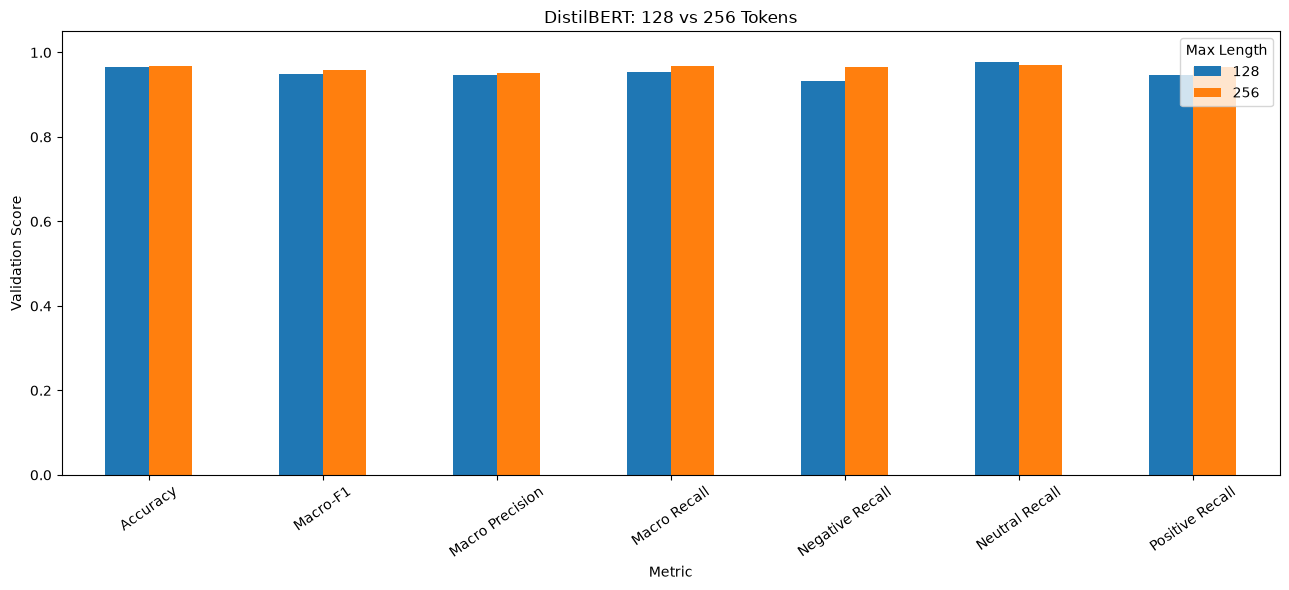

In [85]:
metrics = [
    "val_accuracy",
    "val_macro_f1",
    "val_macro_precision",
    "val_macro_recall",
    "val_negative_recall",
    "val_neutral_recall",
    "val_positive_recall"
]

performance_df = comparison_df.set_index("max_length")[metrics].T

performance_df.index = [
    "Accuracy",
    "Macro-F1",
    "Macro Precision",
    "Macro Recall",
    "Negative Recall",
    "Neutral Recall",
    "Positive Recall"
]

ax = performance_df.plot(
    kind="bar",
    figsize=(13, 6),
    rot=35
)

ax.set_title("DistilBERT: 128 vs 256 Tokens")
ax.set_ylabel("Validation Score")
ax.set_xlabel("Metric")
ax.set_ylim(0, 1.05)
ax.legend(title="Max Length")

plt.tight_layout()

plt.savefig(
    "../figures/sequence_length_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

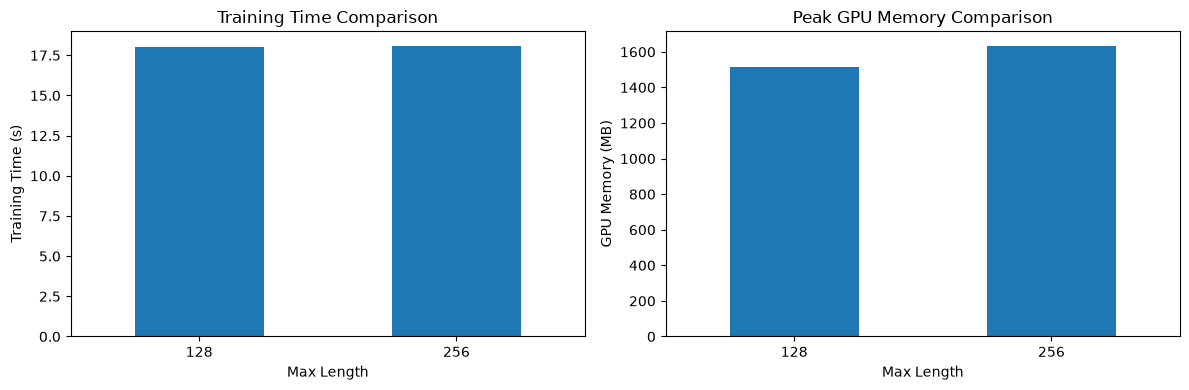

In [86]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

comparison_df.plot(
    x="max_length",
    y="training_time_s",
    kind="bar",
    ax=axes[0],
    legend=False
)

axes[0].set_title("Training Time Comparison")
axes[0].set_xlabel("Max Length")
axes[0].set_ylabel("Training Time (s)")
axes[0].tick_params(axis="x", rotation=0)

comparison_df.plot(
    x="max_length",
    y="peak_gpu_memory_mb",
    kind="bar",
    ax=axes[1],
    legend=False
)

axes[1].set_title("Peak GPU Memory Comparison")
axes[1].set_xlabel("Max Length")
axes[1].set_ylabel("GPU Memory (MB)")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()

plt.savefig(
    "../figures/sequence_length_resource_usage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [87]:
checkpoint_paths = {
    int(row["max_length"]): row["best_checkpoint"]
    for _, row in comparison_df.iterrows()
}

checkpoint_paths

{128: '../models/length_resource_experiment_128/checkpoint-339',
 256: '../models/length_resource_experiment_256/checkpoint-339'}

In [88]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")


def predict_checkpoint(checkpoint_path, max_length, sentences, batch_size=16):
    model = AutoModelForSequenceClassification.from_pretrained(
        checkpoint_path
    ).to(device)

    model.eval()

    predictions = []

    try:
        with torch.inference_mode():
            for start in range(0, len(sentences), batch_size):
                batch = sentences[start:start + batch_size]

                encoded = tokenizer(
                    batch,
                    truncation=True,
                    max_length=max_length,
                    padding=True,
                    return_tensors="pt"
                )

                encoded = {
                    key: value.to(device)
                    for key, value in encoded.items()
                }

                logits = model(**encoded).logits

                batch_predictions = torch.argmax(
                    logits,
                    dim=-1
                )

                predictions.extend(
                    batch_predictions.cpu().tolist()
                )

    finally:
        del model

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    return np.array(predictions)

In [89]:
validation = val_df.reset_index(drop=True).copy()

sentences = validation["sentence"].tolist()

pred_128 = predict_checkpoint(
    checkpoint_paths[128],
    128,
    sentences
)

pred_256 = predict_checkpoint(
    checkpoint_paths[256],
    256,
    sentences
)

print("128 predictions:", pred_128.shape)
print("256 predictions:", pred_256.shape)

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 11797.05it/s]


128 predictions: (226,)
256 predictions: (226,)


In [90]:
for max_length, predictions in [(128, pred_128), (256, pred_256)]:
    macro_f1 = f1_score(
        validation["label"],
        predictions,
        average="macro"
    )

    previous_f1 = comparison_df.loc[
        comparison_df["max_length"] == max_length,
        "val_macro_f1"
    ].iloc[0]

    print("Max Length:", max_length)
    print("Current Macro-F1:", macro_f1)
    print("Previous Macro-F1:", previous_f1)
    print("Match:", np.isclose(macro_f1, previous_f1))

Max Length: 128
Current Macro-F1: 0.9499583541562552
Previous Macro-F1: 0.9499583541562552
Match: True
Max Length: 256
Current Macro-F1: 0.9587973573853675
Previous Macro-F1: 0.9587973573853675
Match: True


In [91]:
disagreement_df = validation[
    ["sentence", "label", "token_count"]
].copy()

disagreement_df = disagreement_df.rename(
    columns={"label": "actual_label"}
)

disagreement_df["prediction_128"] = pred_128
disagreement_df["prediction_256"] = pred_256

disagreement_df["same_prediction"] = (
    disagreement_df["prediction_128"]
    == disagreement_df["prediction_256"]
)

disagreement_df["correct_128"] = (
    disagreement_df["prediction_128"]
    == disagreement_df["actual_label"]
)

disagreement_df["correct_256"] = (
    disagreement_df["prediction_256"]
    == disagreement_df["actual_label"]
)

disagreement_df.head()

,sentence,actual_label,token_count,prediction_128,prediction_256,same_prediction,correct_128,correct_256
0,Aldata said that there are still a number of o...,1,43,1,1,True,True,True
1,- Operating profit rose by 26.9 % to EUR 105.8...,2,24,2,2,True,True,True
2,Diluted earnings per share ( EPS ) rose to EUR...,2,24,2,2,True,True,True
3,Finnish technology company Raute Corporation (...,0,33,0,0,True,True,True
4,The acquisition was financed with $ 2.56 billi...,1,23,1,1,True,True,True


In [92]:
conditions = [
    disagreement_df["correct_128"] & disagreement_df["correct_256"],
    ~disagreement_df["correct_128"] & ~disagreement_df["correct_256"],
    disagreement_df["correct_128"] & ~disagreement_df["correct_256"],
    ~disagreement_df["correct_128"] & disagreement_df["correct_256"]
]

choices = [
    "Both Correct",
    "Both Wrong",
    "Only 128 Correct",
    "Only 256 Correct"
]

disagreement_df["group"] = np.select(
    conditions,
    choices,
    default="Unknown"
)

group_counts = disagreement_df["group"].value_counts()

print(group_counts)

group
Both Correct        217
Both Wrong            6
Only 256 Correct      2
Only 128 Correct      1
Name: count, dtype: int64


In [93]:
disagreement_count = (~disagreement_df["same_prediction"]).sum()

disagreement_rate = (
    disagreement_count / len(disagreement_df) * 100
)

print("Disagreement Count:", disagreement_count)
print(f"Disagreement Rate: {disagreement_rate:.2f}%")

Disagreement Count: 3
Disagreement Rate: 1.33%


In [94]:
different_predictions = disagreement_df[
    disagreement_df["same_prediction"] == False
].copy()

display(
    different_predictions[
        [
            "sentence",
            "actual_label",
            "prediction_128",
            "prediction_256",
            "token_count",
            "group"
        ]
    ]
)

,sentence,actual_label,prediction_128,prediction_256,token_count,group
62,Systeemitiimi 's sales and project resources w...,2,1,2,25,Only 256 Correct
146,"In the first quarter of 2008 , Sacanfil 's net...",1,1,2,36,Only 128 Correct
191,The company said that sales in the three month...,0,2,0,41,Only 256 Correct


In [95]:
different_predictions["token_count"].describe()

count     3.000000
mean     34.000000
std       8.185353
min      25.000000
25%      30.500000
50%      36.000000
75%      38.500000
max      41.000000
Name: token_count, dtype: float64

In [96]:
different_predictions.groupby("actual_label")["token_count"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
actual_label,,,,,
0,1,41.0,41.0,41,41
1,1,36.0,36.0,36,36
2,1,25.0,25.0,25,25


In [98]:
disagreement_df["truncated_128"] = (
    disagreement_df["token_count"] > 128
)

disagreement_df["truncated_256"] = (
    disagreement_df["token_count"] > 256
)

disagreement_df["lost_tokens_128"] = (
    disagreement_df["token_count"] - 128
).clip(lower=0)

disagreement_df["lost_tokens_256"] = (
    disagreement_df["token_count"] - 256
).clip(lower=0)


tokens_128 = tokenizer(
    sentences,
    truncation=True,
    max_length=128,
    padding=False
)["input_ids"]

tokens_256 = tokenizer(
    sentences,
    truncation=True,
    max_length=256,
    padding=False
)["input_ids"]

identical_sequences = [
    ids_128 == ids_256
    for ids_128, ids_256 in zip(tokens_128, tokens_256)
]

print("Identical sequences:", sum(identical_sequences))
print("Total sequences:", len(identical_sequences))
print("All identical:", all(identical_sequences))

Identical sequences: 226
Total sequences: 226
All identical: True


In [99]:
disagreement_df.to_csv(
    "../reports/prediction_disagreement.csv",
    index=False
)

print("Saved:", len(disagreement_df), "validation samples")

Saved: 226 validation samples
